# Retail Demand Forecasting

## Introduction

Accurate demand forecasting is important for retail businesses to make better decisions about inventory, staffing, promotions, and resource allocation. Retail demand is influenced not only by its historical patterns and seasonality, but also by factors such as promotions, holidays, transactions, and other external variables.

In this project, historical retail demand data is analyzed using **time-series forecasting techniques** to understand demand patterns and generate reliable forecasts. The analysis covers time-series exploration and decomposition, stationarity testing, autocorrelation, baseline forecasting methods, and statistical forecasting models.

Different approaches, including **AR, ARIMA, SARIMA, SARIMAX, and VAR**, are evaluated using appropriate time-based validation and forecast error metrics. The final results are interpreted from both a statistical and business perspective.

## Problem Statement

The objective of this project is to determine:

> **How can historical demand and relevant external factors be used to accurately forecast future retail demand?**

### Key Objectives

- Explore trends, seasonality, and other patterns in retail demand.
- Test for stationarity and analyze autocorrelation.
- Establish naive and seasonal-naive forecasting baselines.
- Develop and compare ARIMA, SARIMA, SARIMAX, and VAR models.
- Incorporate relevant external variables into demand forecasting.
- Evaluate forecasts using time-series validation and error metrics.
- Interpret the forecasting results from a business perspective.




In [15]:


import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.api import VAR
from statsmodels.stats.diagnostic import acorr_ljungbox

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42

In [16]:
from pathlib import Path

DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

required_files = [
    "train.csv",
    "stores.csv",
    "oil.csv",
    "holidays_events.csv",
    "transactions.csv"
]

missing = [f for f in required_files if not (DATA_DIR / f).exists()]

if missing:
    print("Missing files:", missing)
    
else:
    print("All required files are already present.")

All required files are already present.


## 3. Load the raw data and inspect its structure

In [18]:
train = pd.read_csv(DATA_DIR / "train.csv")
stores = pd.read_csv(DATA_DIR / "stores.csv")
oil = pd.read_csv(DATA_DIR / "oil.csv")
holidays = pd.read_csv(DATA_DIR / "holidays_events.csv")
transactions = pd.read_csv(DATA_DIR / "transactions.csv")

print("train:", train.shape)
print("stores:", stores.shape)
print("oil:", oil.shape)
print("holidays:", holidays.shape)
print("transactions:", transactions.shape)

display(train.head())
display(stores.head())
display(oil.head())

train: (3000888, 6)
stores: (54, 5)
oil: (1218, 2)
holidays: (350, 6)
transactions: (83488, 3)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20


In [19]:
# Basic schema and missing-value inspection
for name, df in {
    "train": train,
    "stores": stores,
    "oil": oil,
    "holidays": holidays,
    "transactions": transactions
}.items():
    print(f"\n{name.upper()}")
    print(df.dtypes)
    print("Missing values:")
    print(df.isna().sum().sort_values(ascending=False).head(10))


TRAIN
id               int64
date            object
store_nbr        int64
family          object
sales          float64
onpromotion      int64
dtype: object
Missing values:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

STORES
store_nbr     int64
city         object
state        object
type         object
cluster       int64
dtype: object
Missing values:
store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64

OIL
date           object
dcoilwtico    float64
dtype: object
Missing values:
dcoilwtico    43
date           0
dtype: int64

HOLIDAYS
date           object
type           object
locale         object
locale_name    object
description    object
transferred      bool
dtype: object
Missing values:
date           0
type           0
locale         0
locale_name    0
description    0
transferred    0
dtype: int64

TRANSACTIONS
date            object
store_nbr        int64
transaction

## 4. Data cleaning and date handling

The raw data contains dates as strings and some missing oil-price observations.

For the forecasting problem, missing daily oil prices are handled by time interpolation followed by forward/backward filling.

In [21]:
# Standardize date columns
train["date"] = pd.to_datetime(train["date"])
oil["date"] = pd.to_datetime(oil["date"])
holidays["date"] = pd.to_datetime(holidays["date"])
transactions["date"] = pd.to_datetime(transactions["date"])

# Oil prices: interpolate missing observations in chronological order
oil = oil.sort_values("date").copy()
oil["dcoilwtico"] = oil["dcoilwtico"].interpolate(method="linear")
oil["dcoilwtico"] = oil["dcoilwtico"].ffill().bfill()

# Remove duplicate dates from oil if any exist
oil = oil.groupby("date", as_index=False)["dcoilwtico"].mean()

print(oil.isna().sum())

date          0
dcoilwtico    0
dtype: int64


## 5. Choose an interpretable store × product-family series

In [23]:
# Coverage table: identify combinations with substantial history
coverage = (
    train.groupby(["store_nbr", "family"])
    .agg(
        n_days=("date", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        total_sales=("sales", "sum")
    )
    .reset_index()
    .sort_values(["n_days", "total_sales"], ascending=False)
)

display(coverage.head(20))

,store_nbr,family,n_days,first_date,last_date,total_sales
1431,44,GROCERY I,1684,2013-01-01,2017-08-15,1.638606e+07
1464,45,GROCERY I,1684,2013-01-01,2017-08-15,1.634975e+07
1530,47,GROCERY I,1684,2013-01-01,2017-08-15,1.551453e+07
1497,46,GROCERY I,1684,2013-01-01,2017-08-15,1.434226e+07
1422,44,BEVERAGES,1684,2013-01-01,2017-08-15,1.341786e+07
78,3,GROCERY I,1684,2013-01-01,2017-08-15,1.297047e+07
1563,48,GROCERY I,1684,2013-01-01,2017-08-15,1.283099e+07
1455,45,BEVERAGES,1684,2013-01-01,2017-08-15,1.137035e+07
69,3,BEVERAGES,1684,2013-01-01,2017-08-15,1.135159e+07
1596,49,GROCERY I,1684,2013-01-01,2017-08-15,1.108798e+07


In [24]:

SELECTED_STORE = int(coverage.iloc[0]["store_nbr"])
SELECTED_FAMILY = coverage.iloc[0]["family"]

print("Selected store:", SELECTED_STORE)
print("Selected family:", SELECTED_FAMILY)

series_raw = train[
    (train["store_nbr"] == SELECTED_STORE) &
    (train["family"] == SELECTED_FAMILY)
].copy()

series_raw = series_raw.sort_values("date")
display(series_raw.head())
display(series_raw.tail())

Selected store: 44
Selected family: GROCERY I


,id,date,store_nbr,family,sales,onpromotion
1266,1266,2013-01-01,44,GROCERY I,0.0,0
3048,3048,2013-01-02,44,GROCERY I,10686.0,0
4830,4830,2013-01-03,44,GROCERY I,7342.0,0
6612,6612,2013-01-04,44,GROCERY I,7250.0,0
8394,8394,2013-01-05,44,GROCERY I,10699.0,0


,id,date,store_nbr,family,sales,onpromotion
2993244,2993244,2017-08-11,44,GROCERY I,9979.0,38
2995026,2995026,2017-08-12,44,GROCERY I,9391.0,39
2996808,2996808,2017-08-13,44,GROCERY I,9811.0,41
2998590,2998590,2017-08-14,44,GROCERY I,8318.0,39
3000372,3000372,2017-08-15,44,GROCERY I,8123.0,37


## 6. Build the modelling table

We combine:
- target sales
- transactions for the selected store
- oil price
- promotion information
- holiday information
- store metadata

Promotion is aggregated to the selected store/family/day level.

In [26]:
# Promotion feature
promo_daily = (
    series_raw.groupby("date", as_index=False)["onpromotion"]
    .sum()
    .rename(columns={"onpromotion": "promotion_count"})
)

# Selected store transactions
txn_daily = transactions[
    transactions["store_nbr"] == SELECTED_STORE
][["date", "transactions"]].copy()

# Store metadata
store_info = stores[stores["store_nbr"] == SELECTED_STORE].copy()

# Holiday/event feature
holiday_daily = holidays[["date", "type", "locale", "locale_name", "transferred"]].copy()

# Use a simple holiday indicator at the national/local level.
holiday_daily["is_holiday"] = (
    (holiday_daily["type"].isin(["Holiday", "Additional", "Event"])) &
    (holiday_daily["transferred"] == False)
).astype(int)

holiday_daily = (
    holiday_daily.groupby("date", as_index=False)["is_holiday"]
    .max()
)

# Base target
model_df = series_raw[["date", "sales"]].copy()

model_df = model_df.merge(promo_daily, on="date", how="left")
model_df = model_df.merge(txn_daily, on="date", how="left")
model_df = model_df.merge(oil, on="date", how="left")
model_df = model_df.merge(holiday_daily, on="date", how="left")

model_df = model_df.sort_values("date").set_index("date")

model_df["promotion_count"] = model_df["promotion_count"].fillna(0)
model_df["is_holiday"] = model_df["is_holiday"].fillna(0)
model_df["dcoilwtico"] = model_df["dcoilwtico"].interpolate().ffill().bfill()

display(model_df.head())
display(model_df.describe().T)

,sales,promotion_count,transactions,dcoilwtico,is_holiday
date,,,,,
2013-01-01,0.0,0,NaN,93.140000,1.0
2013-01-02,10686.0,0,4821.0,93.140000,0.0
2013-01-03,7342.0,0,3618.0,92.970000,0.0
2013-01-04,7250.0,0,4169.0,93.120000,0.0
2013-01-05,10699.0,0,4921.0,93.146667,0.0


,count,mean,std,min,25%,50%,75%,max
sales,1684.0,9730.436483,3576.086090,0.00,7271.000000,8804.000,11645.500,46271.00
promotion_count,1684.0,28.021378,36.347593,0.00,0.000000,10.000,50.000,202.00
transactions,1677.0,4336.966607,729.914193,2333.00,3810.000000,4170.000,4786.000,8359.00
dcoilwtico,1684.0,67.894634,25.690236,26.19,46.378333,53.285,95.785,110.62
is_holiday,1684.0,0.135986,0.342875,0.00,0.000000,0.000,0.000,1.00


## 7. Data-quality checks

In [28]:
print("Index sorted:", model_df.index.is_monotonic_increasing)
print("Duplicate dates:", model_df.index.duplicated().sum())
print("\nMissing values:")
display(model_df.isna().sum())

print("\nTarget summary:")
display(model_df["sales"].describe())

Index sorted: True
Duplicate dates: 0

Missing values:


sales              0
promotion_count    0
transactions       7
dcoilwtico         0
is_holiday         0
dtype: int64


Target summary:


count     1684.000000
mean      9730.436483
std       3576.086090
min          0.000000
25%       7271.000000
50%       8804.000000
75%      11645.500000
max      46271.000000
Name: sales, dtype: float64

## 8. Exploratory analysis — target series

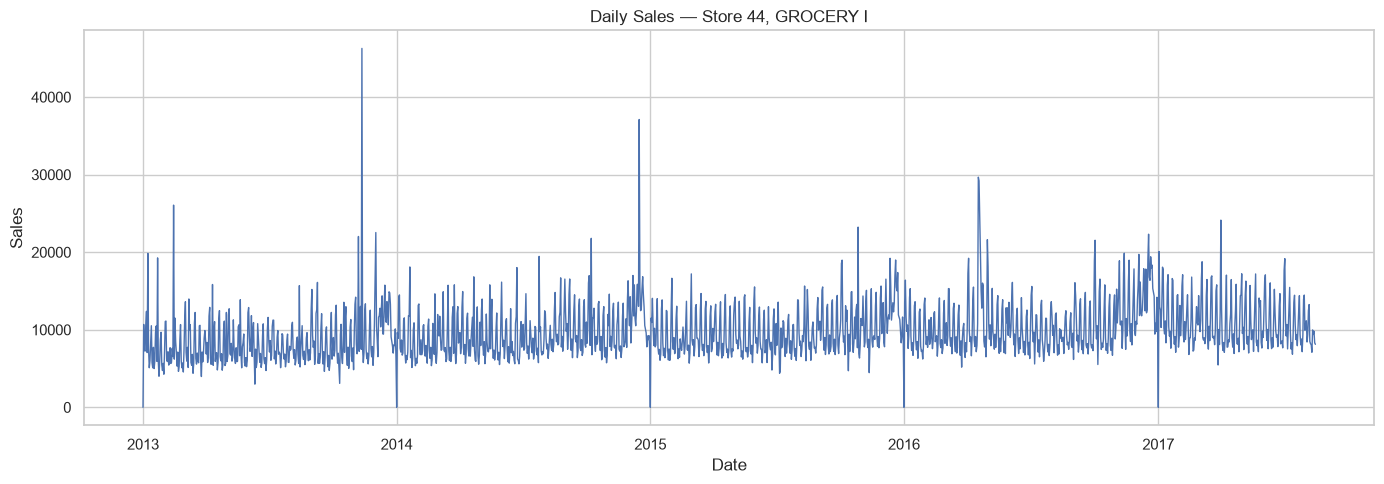

In [30]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(model_df.index, model_df["sales"], linewidth=1)
ax.set_title(f"Daily Sales — Store {SELECTED_STORE}, {SELECTED_FAMILY}")
ax.set_xlabel("Date")
ax.set_ylabel("Sales")
plt.tight_layout()
plt.show()

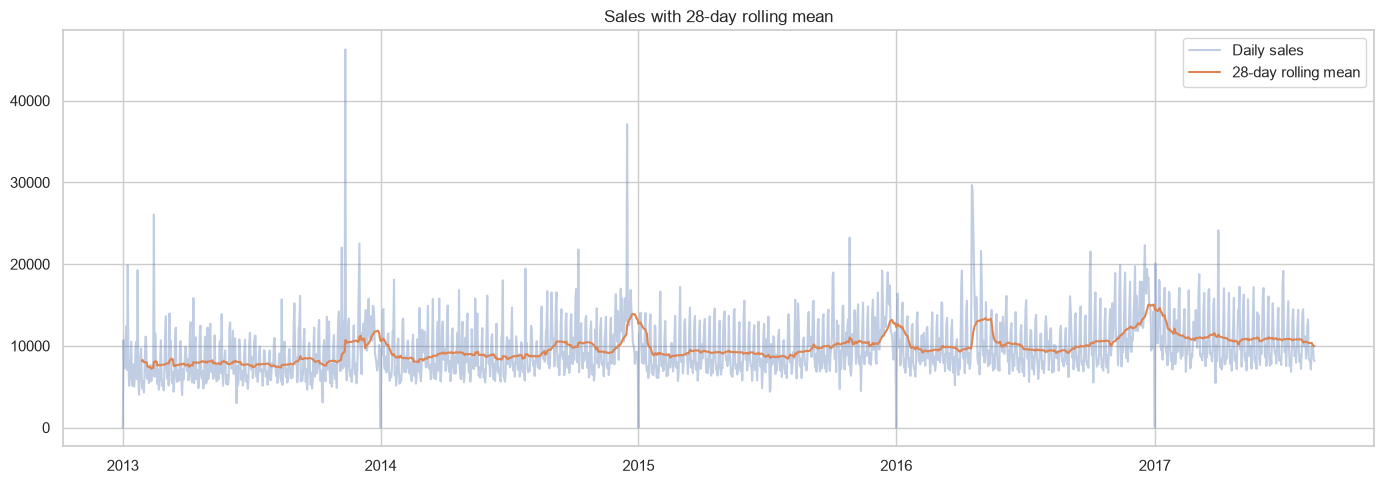

In [31]:
# Rolling statistics help reveal changing level and volatility.
eda = model_df.copy()
eda["rolling_mean_28"] = eda["sales"].rolling(28).mean()
eda["rolling_std_28"] = eda["sales"].rolling(28).std()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(eda.index, eda["sales"], alpha=0.35, label="Daily sales")
ax.plot(eda.index, eda["rolling_mean_28"], label="28-day rolling mean")
ax.set_title("Sales with 28-day rolling mean")
ax.legend()
plt.tight_layout()
plt.show()

## 9. Calendar and business-driver analysis

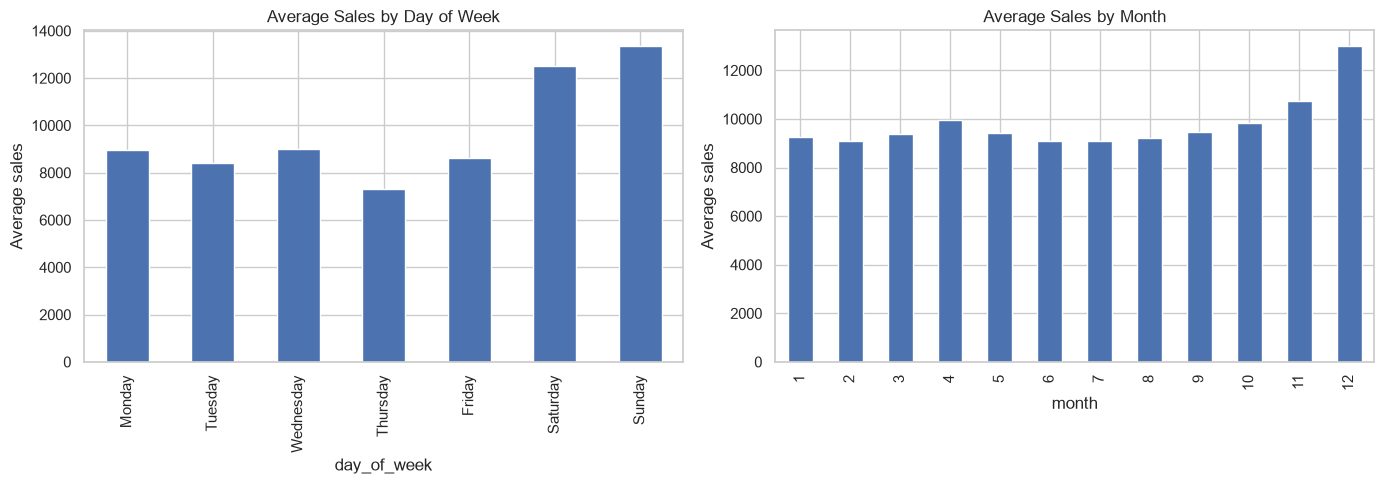

In [33]:
plot_df = model_df.copy()
plot_df["day_of_week"] = plot_df.index.day_name()
plot_df["month"] = plot_df.index.month

dow = plot_df.groupby("day_of_week")["sales"].mean().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
)

monthly = plot_df.groupby("month")["sales"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
dow.plot(kind="bar", ax=axes[0])
axes[0].set_title("Average Sales by Day of Week")
axes[0].set_ylabel("Average sales")

monthly.plot(kind="bar", ax=axes[1])
axes[1].set_title("Average Sales by Month")
axes[1].set_ylabel("Average sales")

plt.tight_layout()
plt.show()

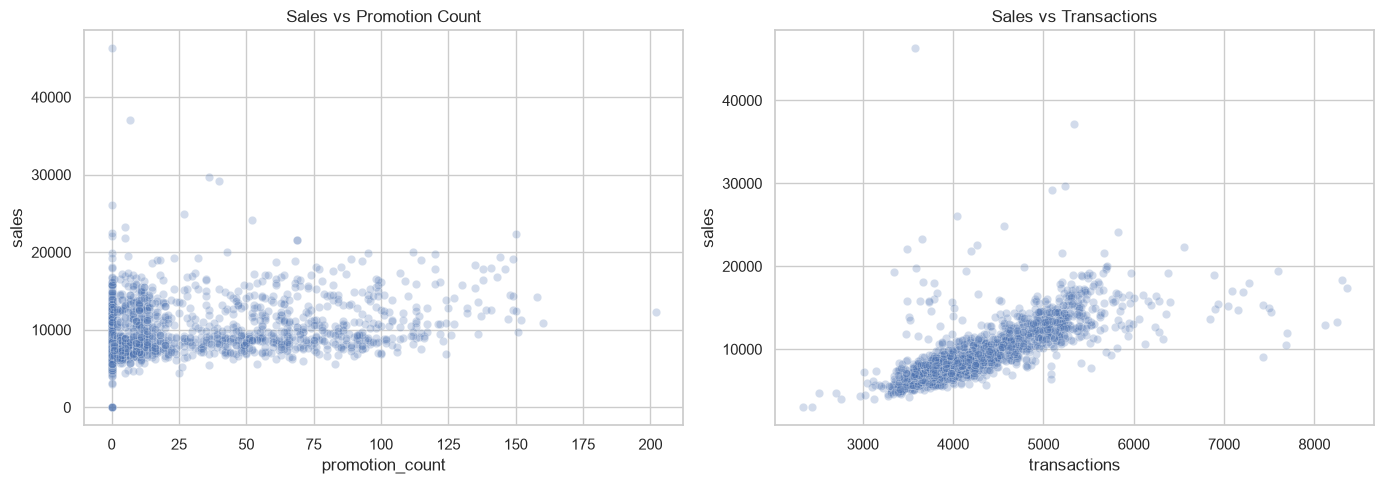

Correlation matrix:


,sales,promotion_count,transactions,dcoilwtico,is_holiday
sales,1.000000,0.273869,0.706413,-0.229777,0.123315
promotion_count,0.273869,1.000000,0.131788,-0.604468,0.052497
transactions,0.706413,0.131788,1.000000,-0.108558,0.167006
dcoilwtico,-0.229777,-0.604468,-0.108558,1.000000,-0.020563
is_holiday,0.123315,0.052497,0.167006,-0.020563,1.000000


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=model_df.reset_index(),
    x="promotion_count",
    y="sales",
    alpha=0.25,
    ax=axes[0]
)
axes[0].set_title("Sales vs Promotion Count")

sns.scatterplot(
    data=model_df.reset_index(),
    x="transactions",
    y="sales",
    alpha=0.25,
    ax=axes[1]
)
axes[1].set_title("Sales vs Transactions")

plt.tight_layout()
plt.show()

print("Correlation matrix:")
display(model_df[["sales", "promotion_count", "transactions", "dcoilwtico", "is_holiday"]].corr())

## 10. Time-series decomposition

Daily retail data has strong weekly behaviour. We therefore use a weekly seasonal period of 7 for the decomposition.


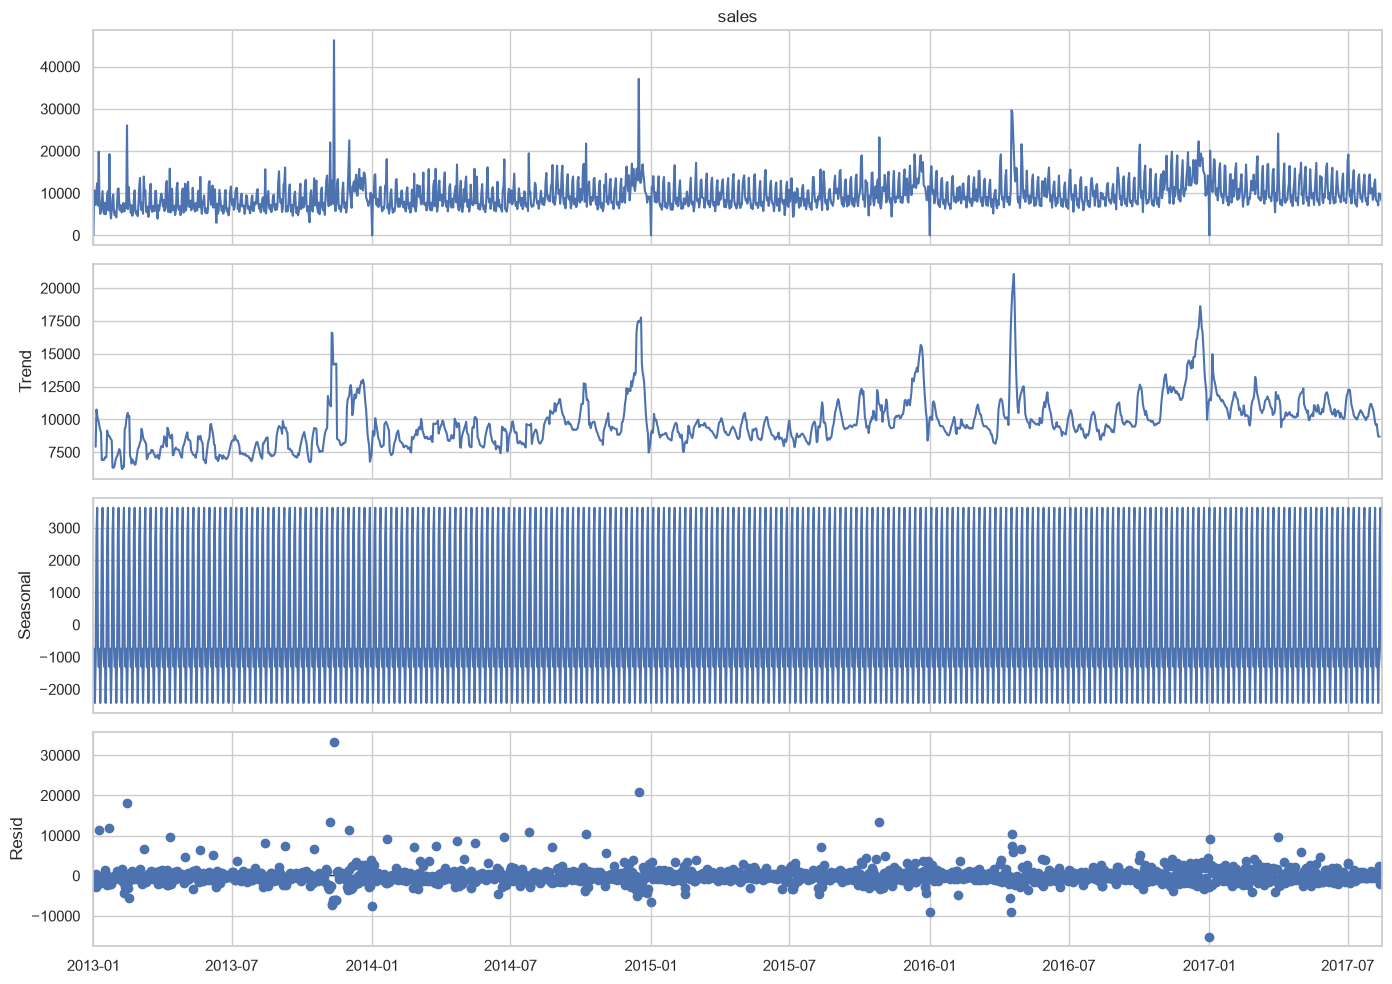

In [170]:


# Make sure the index is datetime
model_df.index = pd.to_datetime(model_df.index)

# Convert to daily frequency
sales_daily = model_df["sales"].asfreq("D")

# Fill missing daily observations
sales_daily = sales_daily.interpolate(method="time")

# Handle any missing values at the beginning/end
sales_daily = sales_daily.ffill().bfill()

# Seasonal decomposition
decomp = seasonal_decompose(
    sales_daily,
    model="additive",
    period=7
)

# Plot
fig = decomp.plot()
fig.set_size_inches(14, 10)
plt.tight_layout()
plt.show()

In [54]:
def stationarity_report(series, name="Series"):
    x = pd.Series(series).dropna()

    adf_stat, adf_p, _, _, adf_crit, _ = adfuller(x, autolag="AIC")
    try:
        kpss_stat, kpss_p, _, kpss_crit = kpss(
            x, regression="c", nlags="auto"
        )
    except Exception:
        kpss_stat, kpss_p, kpss_crit = np.nan, np.nan, {}

    return pd.Series({
        "series": name,
        "ADF statistic": adf_stat,
        "ADF p-value": adf_p,
        "KPSS statistic": kpss_stat,
        "KPSS p-value": kpss_p
    })

display(stationarity_report(model_df["sales"], "Original sales"))

series            Original sales
ADF statistic          -4.924952
ADF p-value             0.000031
KPSS statistic          4.727782
KPSS p-value                0.01
dtype: object

In [56]:
# Automatic interpretation of the stationarity evidence
adf_p = adfuller(model_df["sales"].dropna(), autolag="AIC")[1]
try:
    kpss_p = kpss(model_df["sales"].dropna(), regression="c", nlags="auto")[1]
except Exception:
    kpss_p = np.nan

print("INTERPRETATION")
if adf_p < 0.05 and (np.isnan(kpss_p) or kpss_p >= 0.05):
    print("The tests provide evidence consistent with stationarity.")
elif adf_p >= 0.05 and (np.isnan(kpss_p) or kpss_p < 0.05):
    print("The tests provide evidence consistent with non-stationarity, supporting the use of differencing.")
else:
    print("The tests give mixed evidence. Use the plot and differenced-series diagnostics together with the p-values.")

INTERPRETATION
The tests give mixed evidence. Use the plot and differenced-series diagnostics together with the p-values.


series            First-differenced sales
ADF statistic                  -15.160692
ADF p-value                           0.0
KPSS statistic                   0.058146
KPSS p-value                          0.1
dtype: object

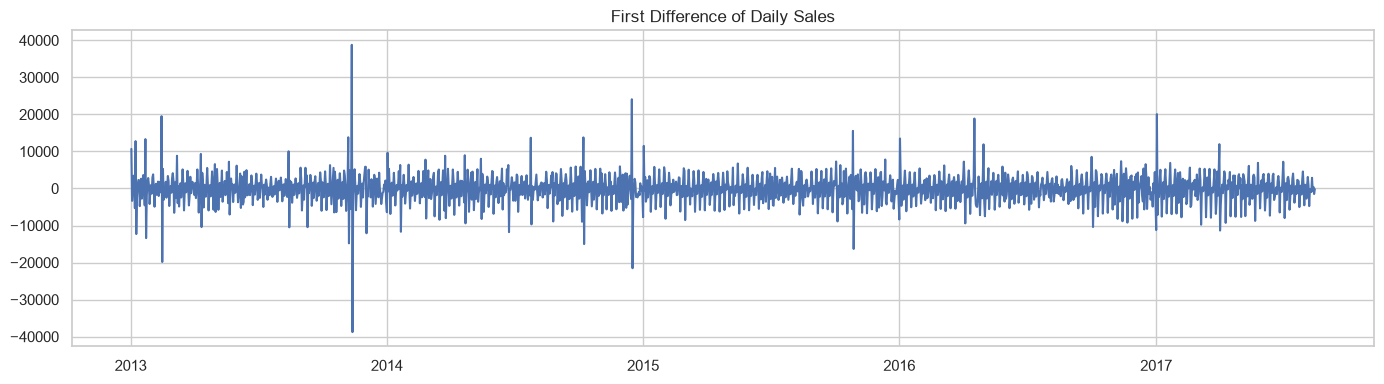

In [58]:
# First difference
model_df["sales_diff_1"] = model_df["sales"].diff()

display(stationarity_report(model_df["sales_diff_1"], "First-differenced sales"))

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(model_df.index, model_df["sales_diff_1"])
ax.set_title("First Difference of Daily Sales")
plt.tight_layout()
plt.show()

In [60]:
adf_p_diff = adfuller(model_df["sales_diff_1"].dropna(), autolag="AIC")[1]
try:
    kpss_p_diff = kpss(model_df["sales_diff_1"].dropna(), regression="c", nlags="auto")[1]
except Exception:
    kpss_p_diff = np.nan

print("INTERPRETATION")
if adf_p_diff < 0.05 and (np.isnan(kpss_p_diff) or kpss_p_diff >= 0.05):
    print("After first differencing, the evidence is broadly consistent with stationarity.")
    print("This supports using d=1 in an ARIMA-family model.")
else:
    print("First differencing has not produced completely clear stationarity evidence; inspect the ACF/PACF and consider whether additional transformation is appropriate.")

INTERPRETATION
After first differencing, the evidence is broadly consistent with stationarity.
This supports using d=1 in an ARIMA-family model.


## 12. ACF and PACF



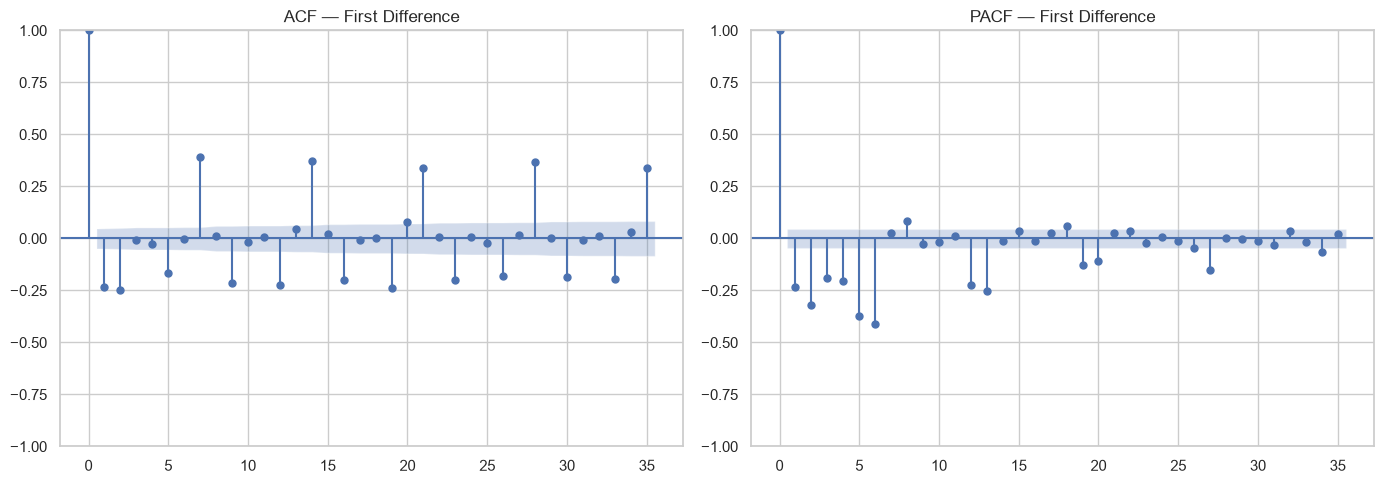

In [63]:
stationary_series = model_df["sales_diff_1"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_acf(stationary_series, lags=35, ax=axes[0])
plot_pacf(stationary_series, lags=35, ax=axes[1], method="ywm")
axes[0].set_title("ACF — First Difference")
axes[1].set_title("PACF — First Difference")
plt.tight_layout()
plt.show()

## 13. Chronological train / validation / test split

In [65]:
# Final 60 days are kept as an untouched test set.
TEST_DAYS = 60
VALIDATION_DAYS = 60

series = model_df["sales"].asfreq("D").ffill()

train_end = len(series) - TEST_DAYS - VALIDATION_DAYS
val_end = len(series) - TEST_DAYS

train_series = series.iloc[:train_end]
val_series = series.iloc[train_end:val_end]
test_series = series.iloc[val_end:]

print("Train:", train_series.index.min(), "to", train_series.index.max(), len(train_series))
print("Validation:", val_series.index.min(), "to", val_series.index.max(), len(val_series))
print("Test:", test_series.index.min(), "to", test_series.index.max(), len(test_series))

Train: 2013-01-01 00:00:00 to 2017-04-17 00:00:00 1568
Validation: 2017-04-18 00:00:00 to 2017-06-16 00:00:00 60
Test: 2017-06-17 00:00:00 to 2017-08-15 00:00:00 60


## 14. Evaluation metrics

In [67]:
def smape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    denom = np.abs(y_true) + np.abs(y_pred)
    return np.mean(2 * np.abs(y_pred - y_true) / np.where(denom == 0, 1, denom)) * 100

def evaluate_forecast(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "sMAPE (%)": smape(y_true, y_pred)
    }

results = []

## 15. Baseline 1 — Naive forecast

In [69]:
naive_pred = pd.Series(
    train_series.iloc[-1],
    index=val_series.index
)

results.append(evaluate_forecast(val_series, naive_pred, "Naive"))

display(pd.DataFrame(results))

,Model,MAE,RMSE,sMAPE (%)
0,Naive,2535.383333,3535.176679,23.167271


## 16. Baseline 2 — Seasonal naive forecast

In [71]:
# Weekly seasonal naive: forecast each day using the value from 7 days earlier.
history_for_seasonal = pd.concat([train_series, val_series])

seasonal_naive_pred = history_for_seasonal.shift(7).loc[val_series.index]

results.append(
    evaluate_forecast(val_series, seasonal_naive_pred, "Seasonal Naive (7)")
)

display(pd.DataFrame(results))

,Model,MAE,RMSE,sMAPE (%)
0,Naive,2535.383333,3535.176679,23.167271
1,Seasonal Naive (7),1581.816667,2374.425871,13.740684


## 17. Autoregression — AR(p)

In [73]:
# Fit a deliberately simple AR model using recent lags.
ar_model = AutoReg(
    train_series,
    lags=14,
    trend="ct",
    old_names=False
).fit()

ar_pred = ar_model.predict(
    start=len(train_series),
    end=len(train_series) + len(val_series) - 1
)

ar_pred.index = val_series.index

results.append(evaluate_forecast(val_series, ar_pred, "AR(14)"))

display(pd.DataFrame(results).sort_values("RMSE"))

,Model,MAE,RMSE,sMAPE (%)
1,Seasonal Naive (7),1581.816667,2374.425871,13.740684
2,AR(14),1949.666117,2385.552829,18.071095
0,Naive,2535.383333,3535.176679,23.167271


## 18. ARIMA

In [75]:
# A small, interpretable candidate rather than a huge grid search.
# The order can be refined after looking at the ACF/PACF diagnostics.
arima_model = ARIMA(
    train_series,
    order=(2, 1, 2)
).fit()

arima_pred = arima_model.forecast(len(val_series))
arima_pred.index = val_series.index

results.append(evaluate_forecast(val_series, arima_pred, "ARIMA(2,1,2)"))

display(pd.DataFrame(results).sort_values("RMSE"))

,Model,MAE,RMSE,sMAPE (%)
1,Seasonal Naive (7),1581.816667,2374.425871,13.740684
2,AR(14),1949.666117,2385.552829,18.071095
3,"ARIMA(2,1,2)",2542.969643,3036.215456,23.279216
0,Naive,2535.383333,3535.176679,23.167271


## 19. SARIMA

### Why add seasonality?

ARIMA handles non-seasonal temporal dependence, while SARIMA explicitly models repeating seasonal structure:

\[
SARIMA(p,d,q)(P,D,Q)_m.
\]

Here \(m=7\) represents weekly seasonality in daily data.

If SARIMA improves meaningfully over ARIMA and the seasonal-naive benchmark, that is evidence that the model is exploiting information beyond simple repeated weekly values.

In [78]:
# Weekly seasonality is represented with seasonal period m=7.
# Keep the orders modest to avoid an unnecessarily complicated project.
sarima_model = SARIMAX(
    train_series,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_pred = sarima_model.get_forecast(steps=len(val_series)).predicted_mean
sarima_pred.index = val_series.index

results.append(
    evaluate_forecast(val_series, sarima_pred, "SARIMA(1,1,1)(1,1,1,7)")
)

display(pd.DataFrame(results).sort_values("RMSE"))

,Model,MAE,RMSE,sMAPE (%)
4,"SARIMA(1,1,1)(1,1,1,7)",1089.947750,1601.909185,9.903422
1,Seasonal Naive (7),1581.816667,2374.425871,13.740684
2,AR(14),1949.666117,2385.552829,18.071095
3,"ARIMA(2,1,2)",2542.969643,3036.215456,23.279216
0,Naive,2535.383333,3535.176679,23.167271


In [79]:
import warnings
warnings.filterwarnings("ignore")

feature_cols = [
    "promotion_count",
    "transactions",
    "dcoilwtico",
    "is_holiday"
]

features = model_df[feature_cols].asfreq("D")

# Fill operational gaps.
features["promotion_count"] = features["promotion_count"].fillna(0)
features["is_holiday"] = features["is_holiday"].fillna(0)
features["transactions"] = features["transactions"].interpolate().ffill().bfill()
features["dcoilwtico"] = features["dcoilwtico"].interpolate().ffill().bfill()

X_train = features.loc[train_series.index]
X_val = features.loc[val_series.index]

sarimax_model = SARIMAX(
    train_series,
    exog=X_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarimax_forecast = sarimax_model.get_forecast(
    steps=len(val_series),
    exog=X_val
)

sarimax_pred = sarimax_forecast.predicted_mean
sarimax_pred.index = val_series.index

results.append(
    evaluate_forecast(val_series, sarimax_pred, "SARIMAX + business drivers")
)

display(pd.DataFrame(results).sort_values("RMSE"))

,Model,MAE,RMSE,sMAPE (%)
4,"SARIMA(1,1,1)(1,1,1,7)",1089.947750,1601.909185,9.903422
5,SARIMAX + business drivers,1501.976374,1858.823538,14.796511
1,Seasonal Naive (7),1581.816667,2374.425871,13.740684
2,AR(14),1949.666117,2385.552829,18.071095
3,"ARIMA(2,1,2)",2542.969643,3036.215456,23.279216
0,Naive,2535.383333,3535.176679,23.167271


## 21. Comparing Validation

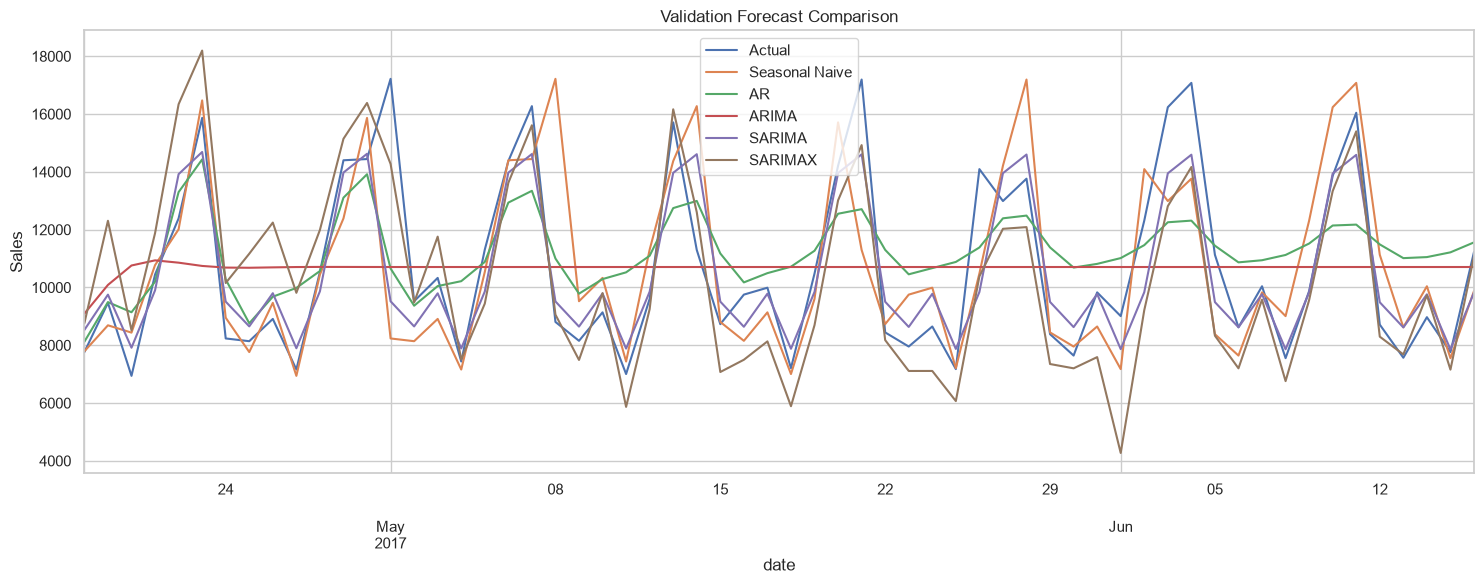

In [81]:
comparison = pd.DataFrame({
    "Actual": val_series,
    "Seasonal Naive": seasonal_naive_pred,
    "AR": ar_pred,
    "ARIMA": arima_pred,
    "SARIMA": sarima_pred,
    "SARIMAX": sarimax_pred
})

fig, ax = plt.subplots(figsize=(15, 6))
comparison.plot(ax=ax)
ax.set_title("Validation Forecast Comparison")
ax.set_ylabel("Sales")
plt.tight_layout()
plt.show()

## 22. Residual diagnostics for the main SARIMAX model

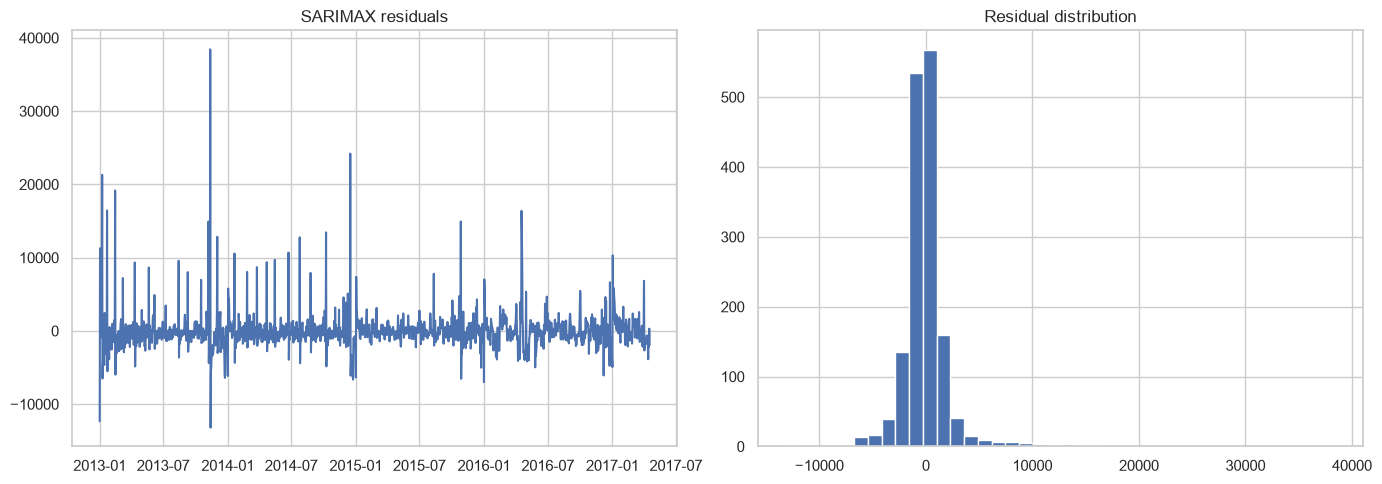

In [83]:
residuals = sarimax_model.resid.dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(residuals)
axes[0].set_title("SARIMAX residuals")
axes[1].hist(residuals, bins=40)
axes[1].set_title("Residual distribution")
plt.tight_layout()
plt.show()

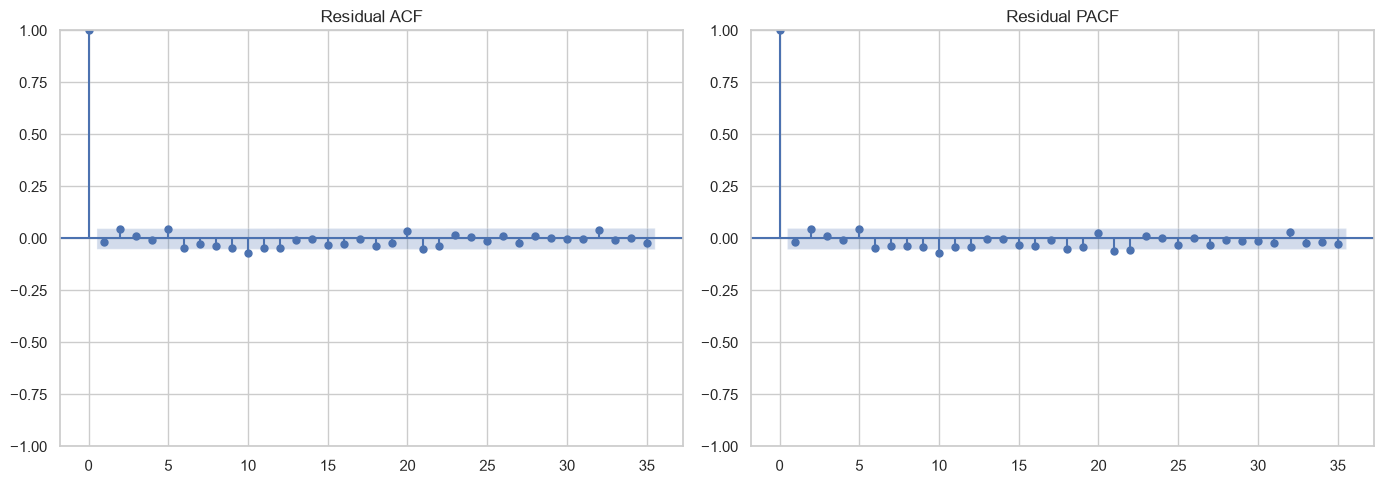

,lb_stat,lb_pvalue
7,12.076824,0.098061
14,31.850323,0.004207
21,43.868460,0.002432
28,47.732010,0.011450


In [84]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_acf(residuals, lags=35, ax=axes[0])
plot_pacf(residuals, lags=35, ax=axes[1], method="ywm")
axes[0].set_title("Residual ACF")
axes[1].set_title("Residual PACF")
plt.tight_layout()
plt.show()

lb = acorr_ljungbox(residuals, lags=[7, 14, 21, 28], return_df=True)
display(lb)

### Residual interpretation

A useful model should leave substantially less serial structure in the residuals than the raw series.

The Ljung–Box test is used as a diagnostic rather than as a standalone model-selection rule.

## 23. Multivariate extension — VAR

In [87]:
var_df = model_df[["sales", "transactions"]].asfreq("D").copy()
var_df["transactions"] = var_df["transactions"].interpolate().ffill().bfill()

# Work with first differences to reduce trend/non-stationarity.
var_stationary = var_df.diff().dropna()

var_train = var_stationary.iloc[:len(train_series)-1]
var_val = var_stationary.iloc[len(train_series)-1:len(train_series)-1+len(val_series)]

print("VAR training shape:", var_train.shape)
display(var_stationary.head())

VAR training shape: (1567, 2)


,sales,transactions
date,,
2013-01-02,10686.0,0.0
2013-01-03,-3344.0,-1203.0
2013-01-04,-92.0,551.0
2013-01-05,3449.0,752.0
2013-01-06,1674.0,4.0


In [88]:
# Select a small lag order using AIC.
import warnings
warnings.filterwarnings("ignore")

var_selection = VAR(var_train).select_order(maxlags=14)
print(var_selection.summary())

selected_lag = var_selection.aic
if selected_lag is None or np.isnan(selected_lag):
    selected_lag = 7

selected_lag = int(max(1, min(selected_lag, 14)))
print("Selected VAR lag:", selected_lag)

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0        29.10       29.11   4.355e+12       29.10
1        28.87       28.90   3.469e+12       28.88
2        28.57       28.61   2.567e+12       28.59
3        28.51       28.56   2.407e+12       28.53
4        28.37       28.44   2.103e+12       28.40
5        27.99       28.06   1.425e+12       28.01
6        27.68       27.77   1.048e+12       27.71
7        27.58       27.68   9.483e+11       27.62
8        27.55       27.67   9.259e+11       27.60
9        27.55       27.68   9.257e+11       27.60
10       27.54       27.68   9.124e+11       27.59
11       27.53       27.69   9.026e+11       27.59
12       27.49       27.66   8.647e+11       27.55
13       27.44       27.62   8.227e+11       27.50
14      27.42*      27.62*  8.079e+11*      27.49*
--------------------------------------------------
Selected VAR lag: 14


In [89]:
import warnings
warnings.filterwarnings("ignore")

var_model = VAR(var_train).fit(selected_lag)

var_forecast_diff = var_model.forecast(
    var_train.values[-selected_lag:],
    steps=len(var_val)
)

var_forecast_diff = pd.DataFrame(
    var_forecast_diff,
    index=val_series.index,
    columns=var_train.columns
)

# Convert differenced sales forecast back to the original scale.
var_sales_pred = train_series.iloc[-1] + var_forecast_diff["sales"].cumsum()

results.append(
    evaluate_forecast(val_series, var_sales_pred, "VAR")
)

display(pd.DataFrame(results).sort_values("RMSE"))

,Model,MAE,RMSE,sMAPE (%)
4,"SARIMA(1,1,1)(1,1,1,7)",1089.947750,1601.909185,9.903422
5,SARIMAX + business drivers,1501.976374,1858.823538,14.796511
1,Seasonal Naive (7),1581.816667,2374.425871,13.740684
2,AR(14),1949.666117,2385.552829,18.071095
6,VAR,2362.023235,2988.779403,21.497124
3,"ARIMA(2,1,2)",2542.969643,3036.215456,23.279216
0,Naive,2535.383333,3535.176679,23.167271


## 24. Model comparison


,Model,MAE,RMSE,sMAPE (%)
0,"SARIMA(1,1,1)(1,1,1,7)",1089.947750,1601.909185,9.903422
1,SARIMAX + business drivers,1501.976374,1858.823538,14.796511
2,Seasonal Naive (7),1581.816667,2374.425871,13.740684
3,AR(14),1949.666117,2385.552829,18.071095
4,VAR,2362.023235,2988.779403,21.497124
5,"ARIMA(2,1,2)",2542.969643,3036.215456,23.279216
6,Naive,2535.383333,3535.176679,23.167271


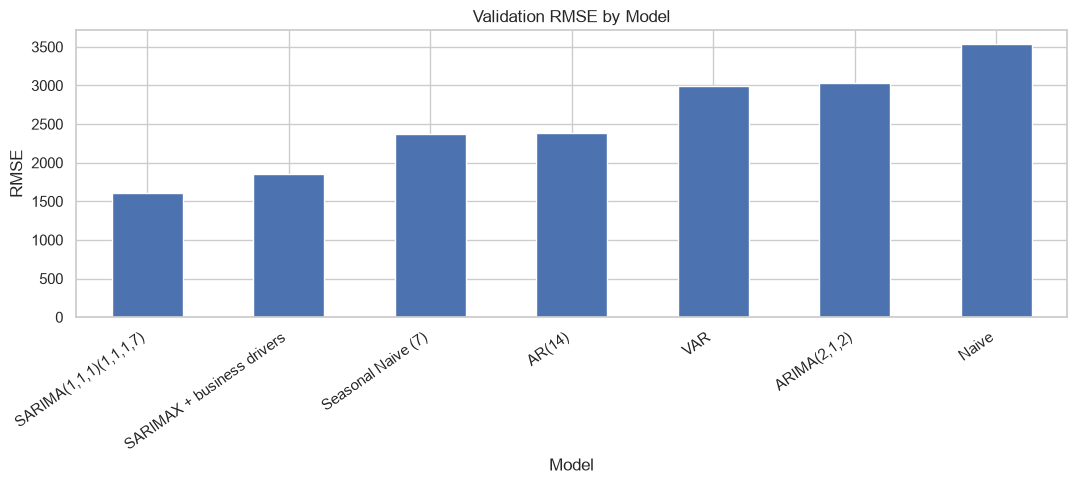

In [91]:
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df)

fig, ax = plt.subplots(figsize=(11, 5))
results_df.set_index("Model")["RMSE"].plot(kind="bar", ax=ax)
ax.set_title("Validation RMSE by Model")
ax.set_ylabel("RMSE")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [92]:
print("INTERPRETATION")
best = results_df.iloc[0]
baseline = results_df.loc[results_df["Model"].eq("Seasonal Naive (7)"), "RMSE"]
if len(baseline):
    improvement = (baseline.iloc[0] - best["RMSE"]) / baseline.iloc[0] * 100
    print(f"Lowest validation RMSE: {best['Model']} ({best['RMSE']:.2f}).")
    print(f"Relative RMSE improvement versus the seasonal-naive baseline: {improvement:.1f}%.")
else:
    print(f"Lowest validation RMSE: {best['Model']} ({best['RMSE']:.2f}).")
print("Use this result together with model complexity, residual diagnostics and forecast availability before making a final production recommendation.")

INTERPRETATION
Lowest validation RMSE: SARIMA(1,1,1)(1,1,1,7) (1601.91).
Relative RMSE improvement versus the seasonal-naive baseline: 32.5%.
Use this result together with model complexity, residual diagnostics and forecast availability before making a final production recommendation.


## 25. Final model selection

In [94]:


best_model_name = results_df.iloc[0]["Model"]
print("Best validation RMSE model:", best_model_name)

Best validation RMSE model: SARIMA(1,1,1)(1,1,1,7)


In [98]:
pre_test_series = series.iloc[:val_end]
X_pre_test = features.loc[pre_test_series.index]
X_test = features.loc[test_series.index]

final_sarimax = SARIMAX(
    pre_test_series,
    exog=X_pre_test,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

final_sarimax_fc = final_sarimax.get_forecast(
    steps=len(test_series),
    exog=X_test
)

final_pred = final_sarimax_fc.predicted_mean
final_ci = final_sarimax_fc.conf_int()

final_pred.index = test_series.index
final_ci.index = test_series.index

final_metrics = evaluate_forecast(
    test_series,
    final_pred,
    "Final SARIMAX"
)

pd.DataFrame([final_metrics])

,Model,MAE,RMSE,sMAPE (%)
0,Final SARIMAX,656.483677,930.222104,6.143998


In [99]:
print("FINAL HOLDOUT SUMMARY")
print(f"Model: {final_metrics['Model']}")
print(f"MAE: {final_metrics['MAE']:.2f}")
print(f"RMSE: {final_metrics['RMSE']:.2f}")
print(f"sMAPE: {final_metrics['sMAPE (%)']:.2f}%")
print("\nInterpretation:")
print("These metrics are calculated on observations that were not used when fitting the final model.")
print("Therefore they provide a more realistic estimate of future forecasting performance than training-set fit statistics.")

FINAL HOLDOUT SUMMARY
Model: Final SARIMAX
MAE: 656.48
RMSE: 930.22
sMAPE: 6.14%

Interpretation:
These metrics are calculated on observations that were not used when fitting the final model.
Therefore they provide a more realistic estimate of future forecasting performance than training-set fit statistics.


## 27. Final holdout forecast with prediction intervals

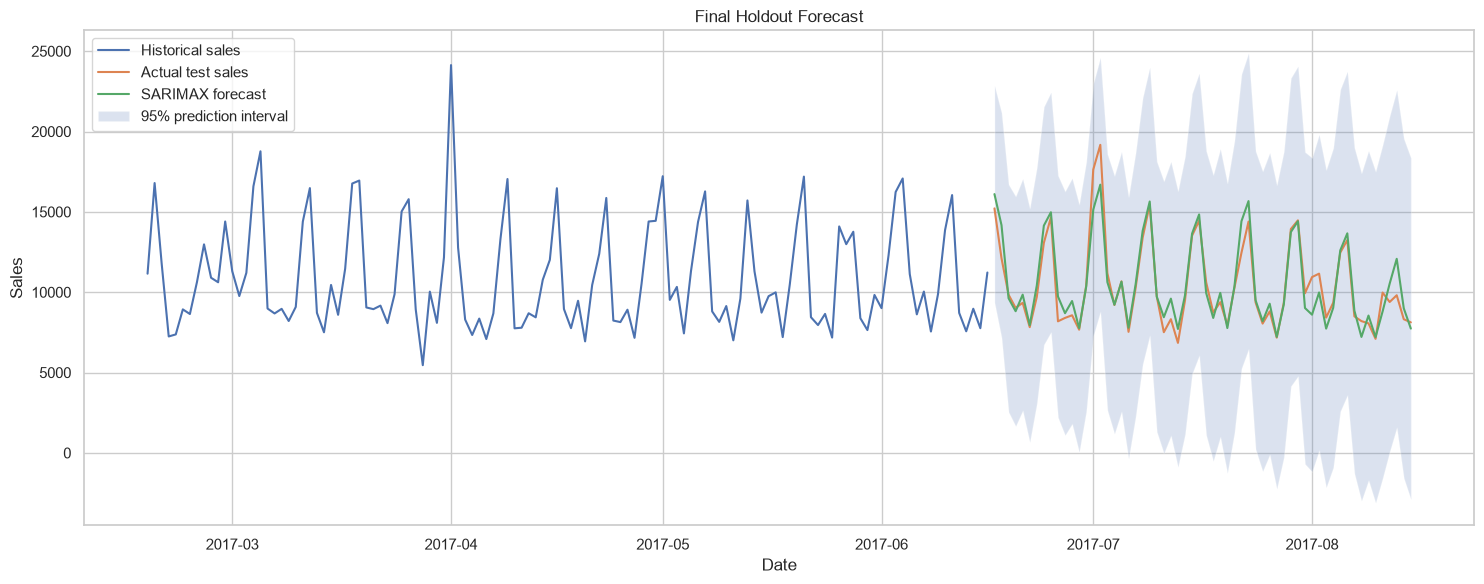

In [101]:
fig, ax = plt.subplots(figsize=(15, 6))

recent_start = max(0, len(pre_test_series) - 120)

ax.plot(
    pre_test_series.iloc[recent_start:].index,
    pre_test_series.iloc[recent_start:],
    label="Historical sales"
)

ax.plot(
    test_series.index,
    test_series,
    label="Actual test sales"
)

ax.plot(
    final_pred.index,
    final_pred,
    label="SARIMAX forecast"
)

ax.fill_between(
    final_ci.index,
    final_ci.iloc[:, 0],
    final_ci.iloc[:, 1],
    alpha=0.20,
    label="95% prediction interval"
)

ax.set_title("Final Holdout Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Sales")
ax.legend()
plt.tight_layout()
plt.show()

## 28. Business interpretation

In [103]:
# Model coefficients are descriptive associations conditional on the SARIMAX specification.
params = final_sarimax.params

coef_rows = [
    p for p in params.index
    if p in feature_cols
]

display(params.loc[coef_rows].sort_values(key=np.abs, ascending=False).to_frame("Coefficient"))

,Coefficient
dcoilwtico,-138.805323
promotion_count,12.552322
is_holiday,12.346276
transactions,2.837128


## 29. Feature importance / business-driver summary

In [105]:
driver_summary = pd.DataFrame({
    "Driver": coef_rows,
    "Coefficient": [params[p] for p in coef_rows]
}).sort_values("Coefficient", key=np.abs, ascending=False)

display(driver_summary)

,Driver,Coefficient
2,dcoilwtico,-138.805323
0,promotion_count,12.552322
3,is_holiday,12.346276
1,transactions,2.837128


## 30. Production-style forecasting function



In [168]:
def fit_and_forecast_sarimax(
    target,
    exog_train,
    exog_future,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7)
):
    model = SARIMAX(
        target,
        exog=exog_train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    forecast = model.get_forecast(
        steps=len(exog_future),
        exog=exog_future
    )

    return {
        "model": model,
        "forecast": forecast.predicted_mean,
        "interval": forecast.conf_int()
    }

